In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    average_precision_score,
    precision_recall_curve)
import warnings
warnings.filterwarnings("ignore")

In [44]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/credit_card_fraud_20000.csv")

In [45]:
df.head()

,TransactionID,TransactionAmount,TransactionHour,DayOfWeek,DistanceFromUsualLocationKM,MerchantCategory,CardPresent,InternationalTransaction,TransactionsLast24Hours,FailedAttempts,AccountAgeDays,PreviousFraudFlag,DeviceTrustScore,Fraud
0,500001,13.56,22,2,6.71,Electronics,1,0,2,0,3373,0,0.675,0
1,500002,38.11,16,0,58.48,Clothing,1,0,1,0,1349,0,0.710,0
2,500003,4.50,18,6,1.48,Online,0,0,1,0,4022,0,0.791,0
3,500004,121.00,5,4,89.45,Clothing,1,0,3,0,1497,0,0.394,0
4,500005,56.73,7,3,9.99,Grocery,1,0,2,1,3546,0,0.684,0


In [46]:
df.shape

(20000, 14)

In [47]:
df.columns

Index(['TransactionID', 'TransactionAmount', 'TransactionHour', 'DayOfWeek',
       'DistanceFromUsualLocationKM', 'MerchantCategory', 'CardPresent',
       'InternationalTransaction', 'TransactionsLast24Hours', 'FailedAttempts',
       'AccountAgeDays', 'PreviousFraudFlag', 'DeviceTrustScore', 'Fraud'],
      dtype='object')

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   TransactionID                20000 non-null  int64  
 1   TransactionAmount            20000 non-null  float64
 2   TransactionHour              20000 non-null  int64  
 3   DayOfWeek                    20000 non-null  int64  
 4   DistanceFromUsualLocationKM  20000 non-null  float64
 5   MerchantCategory             20000 non-null  object 
 6   CardPresent                  20000 non-null  int64  
 7   InternationalTransaction     20000 non-null  int64  
 8   TransactionsLast24Hours      20000 non-null  int64  
 9   FailedAttempts               20000 non-null  int64  
 10  AccountAgeDays               20000 non-null  int64  
 11  PreviousFraudFlag            20000 non-null  int64  
 12  DeviceTrustScore             20000 non-null  float64
 13  Fraud           

In [49]:
df.describe()

,TransactionID,TransactionAmount,TransactionHour,DayOfWeek,DistanceFromUsualLocationKM,CardPresent,InternationalTransaction,TransactionsLast24Hours,FailedAttempts,AccountAgeDays,PreviousFraudFlag,DeviceTrustScore,Fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,510000.500000,49.570664,11.433250,3.001150,19.927828,0.618750,0.060400,2.482100,0.241950,2507.155450,0.015550,0.714936,0.019450
std,5773.647028,63.960805,6.932247,2.002261,20.207316,0.485706,0.238232,1.577024,0.490838,1440.550347,0.123729,0.159263,0.138104
min,500001.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.096000,0.000000
25%,505000.750000,15.040000,5.000000,1.000000,5.667500,0.000000,0.000000,1.000000,0.000000,1263.000000,0.000000,0.610750,0.000000
50%,510000.500000,30.210000,11.000000,3.000000,13.690000,1.000000,0.000000,2.000000,0.000000,2507.500000,0.000000,0.736000,0.000000
75%,515000.250000,59.205000,17.000000,5.000000,27.570000,1.000000,0.000000,3.000000,0.000000,3758.000000,0.000000,0.841000,0.000000
max,520000.000000,1173.220000,23.000000,6.000000,245.430000,1.000000,1.000000,10.000000,4.000000,4999.000000,1.000000,0.999000,1.000000


In [50]:
df.duplicated().sum()

np.int64(0)

In [51]:
df.isnull().sum()

TransactionID                  0
TransactionAmount              0
TransactionHour                0
DayOfWeek                      0
DistanceFromUsualLocationKM    0
MerchantCategory               0
CardPresent                    0
InternationalTransaction       0
TransactionsLast24Hours        0
FailedAttempts                 0
AccountAgeDays                 0
PreviousFraudFlag              0
DeviceTrustScore               0
Fraud                          0
dtype: int64

In [52]:
X = df.drop(["Fraud", "TransactionID"], axis=1)
y = df["Fraud"]

In [53]:
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include="object").columns.tolist()
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['TransactionAmount', 'TransactionHour', 'DayOfWeek', 'DistanceFromUsualLocationKM', 'CardPresent', 'InternationalTransaction', 'TransactionsLast24Hours', 'FailedAttempts', 'AccountAgeDays', 'PreviousFraudFlag', 'DeviceTrustScore']
Categorical Columns: ['MerchantCategory']


In [54]:
from sklearn.model_selection import (train_test_split,RandomizedSearchCV)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16000, 12)
(4000, 12)
(16000,)
(4000,)


In [55]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [65]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = X.select_dtypes(include=["object", "bool"]).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [66]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

xgb_model = ImbPipeline(steps=[
    ("preprocessing", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ))
])

In [67]:
xgb_model.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](12,)","['TransactionAmount','TransactionHour','DayOfWeek',...,'AccountAgeDays', 'PreviousFraudFlag','DeviceTrustScore']"
n_features_in_,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [68]:
# Predictions
y_pred = xgb_model.predict(X_test)
# Prediction probabilities
y_prob = xgb_model.predict_proba(X_test)[:, 1]
print("Predictions:", y_pred[:10])
print("Actual Values:", y_test[:10].values)

Predictions: [0 0 0 0 0 0 0 0 0 0]
Actual Values: [0 0 0 0 0 0 0 0 0 0]


In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.97925
Precision: 0.07142857142857142
Recall: 0.014084507042253521
F1 Score: 0.023529411764705882

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3929
           1       0.07      0.01      0.02        71

    accuracy                           0.98      4000
   macro avg       0.53      0.51      0.51      4000
weighted avg       0.97      0.98      0.97      4000



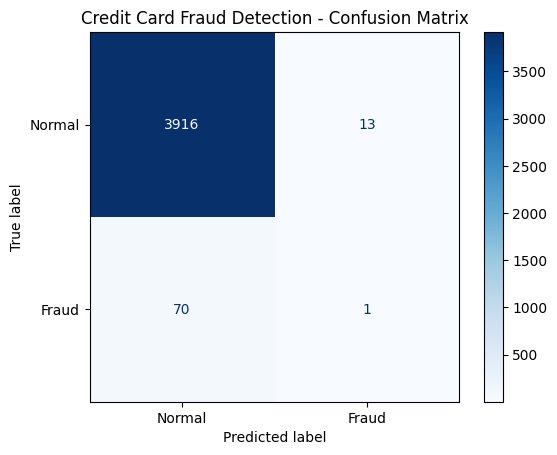

In [70]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"])

disp.plot(cmap="Blues")
plt.title("Credit Card Fraud Detection - Confusion Matrix")
plt.show()

In [71]:
from sklearn.metrics import roc_auc_score, roc_curve
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.6296767625349962


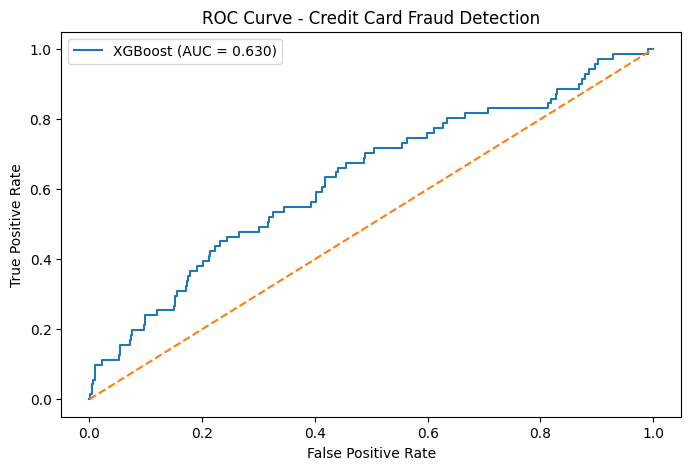

In [72]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Credit Card Fraud Detection")
plt.legend()
plt.show()

In [73]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score)
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
print("PR-AUC Score:", pr_auc)

PR-AUC Score: 0.04007406145090371


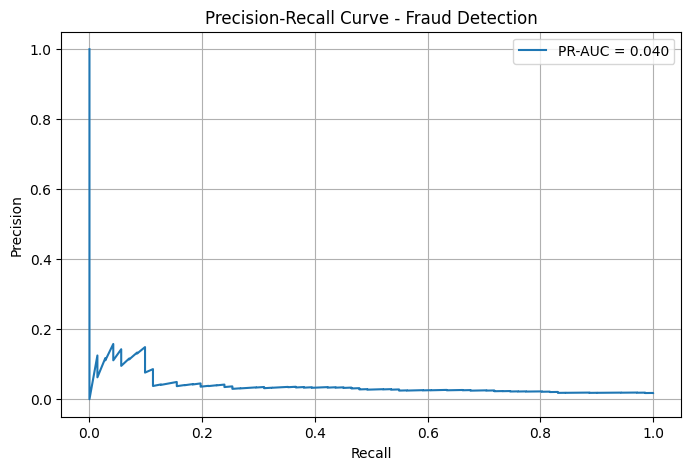

In [74]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Fraud Detection")
plt.legend()
plt.grid()
plt.show()

In [75]:
param_grid = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0]
}

In [76]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=8,
    cv=3,
    scoring="average_precision",
    random_state=42,
    n_jobs=1,
    verbose=1)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__colsample_bytree': [0.8, 1.0], 'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__max_depth': [3, 4, ...], 'classifier__n_estimators': [100, 150, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a 

In [77]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest PR-AUC Score:")
print(random_search.best_score_)

Best Parameters:
{'classifier__subsample': 1.0, 'classifier__n_estimators': 150, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.8}

Best PR-AUC Score:
0.0618705468020195


In [78]:
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

In [79]:
from sklearn.metrics import classification_report, average_precision_score
print("Tuned Model Classification Report:")
print(classification_report(y_test, y_pred_tuned))
print("Tuned Model PR-AUC:",
      average_precision_score(y_test, y_prob_tuned))

Tuned Model Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3929
           1       0.11      0.01      0.03        71

    accuracy                           0.98      4000
   macro avg       0.55      0.51      0.51      4000
weighted avg       0.97      0.98      0.97      4000

Tuned Model PR-AUC: 0.05683268065873823


In [82]:
import pandas as pd
feature_names = (best_model.named_steps["preprocessing"].get_feature_names_out())
importance = (best_model.named_steps["classifier"].feature_importances_)
feature_importance = pd.DataFrame({"Feature": feature_names,"Importance": importance})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
feature_importance.head(10)

,Feature,Importance
16,cat__MerchantCategory_Online,0.219612
14,cat__MerchantCategory_Grocery,0.109835
12,cat__MerchantCategory_Electronics,0.089119
4,num__CardPresent,0.085314
6,num__TransactionsLast24Hours,0.067879
13,cat__MerchantCategory_Fuel,0.064296
11,cat__MerchantCategory_Clothing,0.061709
17,cat__MerchantCategory_Restaurants,0.058314
2,num__DayOfWeek,0.056707
7,num__FailedAttempts,0.034214


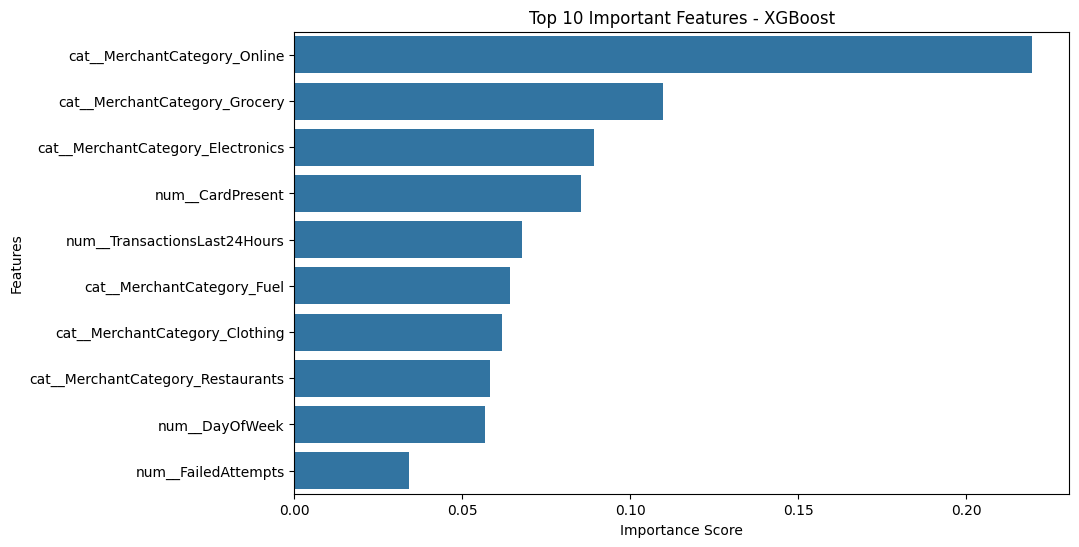

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns
top_features = feature_importance.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature")
plt.title("Top 10 Important Features - XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [85]:
new_transaction = pd.DataFrame([{
    "TransactionAmount": 8500,
    "TransactionHour": 2,
    "DayOfWeek": 6,
    "DistanceFromUsualLocationKM": 250,
    "MerchantCategory": "Electronics",
    "CardPresent": 0,
    "InternationalTransaction": 1,
    "TransactionsLast24Hours": 8,
    "FailedAttempts": 3,
    "AccountAgeDays": 120,
    "PreviousFraudFlag": 1,
    "DeviceTrustScore": 0.2
}])

In [86]:
prediction = best_model.predict(new_transaction)
probability = best_model.predict_proba(new_transaction)[0][1]

if prediction[0] == 1:
    print("Prediction: Fraud Transaction")
else:
    print("Prediction: Normal Transaction")

print("Fraud Probability:", round(probability * 100, 2), "%")

Prediction: Fraud Transaction
Fraud Probability: 86.96 %


In [87]:
import joblib
joblib.dump(best_model, "credit_card_fraud_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [88]:
loaded_model = joblib.load("credit_card_fraud_model.pkl")
loaded_prediction = loaded_model.predict(new_transaction)
print("Loaded Model Prediction:", loaded_prediction)

Loaded Model Prediction: [1]
